In [2]:
import os
from os.path import join as pjoin


In [3]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
from scipy.signal import welch
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import random as rd
from past.utils import old_div

In [4]:
# # this is for my folder setup, you can just ignore it
# freelancer_path = pjoin(mydrive_path,'Freelancer Projects/Projects')
# root_path = pjoin(freelancer_path,'proj 18')
# input_path = pjoin(root_path,'Data')
# # df = pd.read_csv(pjoin(input_path,'CNM_004.csv'),encoding='utf-8')
# os.chdir(root_path)

In [5]:
df = pd.read_csv('Data/CNM_004.csv')

cols = df.loc[0].eq(" accepted")
cols = cols.index[cols]
cols = list(cols)
cols_ori = cols

df_data = df[[" ",*cols]].drop([0])
df_data = df_data.astype(np.double)

df_data['next_row_value'] = df_data[' '].shift(-1)
idx = df_data.loc[df_data['next_row_value'] > df_data[' '] + 2].index

segments = [0]

for i,el in enumerate(idx):
    diff_normal = df_data.loc[el][" "] - df_data.loc[el-1][" "]
    diff_missing = df_data.loc[el+1][" "] - df_data.loc[el][" "]
    segments.append(df_data.loc[el][" "])
    df_data.loc[el+1:,' '] -= diff_missing - diff_normal
df_data = df_data.dropna()
    
df_data.describe()

/var/folders/b7/k9l5l5ss13d27wd57vb8fq4w0000gn/T/ipykernel_35911/2819304030.py:1: DtypeWarning: Columns (0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('Data/CNM_004.csv')


,,C00,C07,C09,C14,C15,C16,C17,C19,C21,...,C60,C75,C82,C83,C84,C87,C89,C90,C91,next_row_value
count,30024.000000,30024.000000,30024.000000,30024.000000,30024.000000,30024.000000,30024.000000,30024.000000,30024.000000,30024.000000,...,30024.000000,30024.000000,30024.000000,30024.000000,30024.000000,30024.000000,30024.000000,30024.000000,30024.000000,30024.000000
mean,749.989551,3.205204,1.328065,4.289124,1.899558,2.189658,0.634931,0.580184,0.006437,12.483819,...,1.046443,1.057800,4.134213,3.686736,2.575230,0.515123,20.745605,13.881037,17.271095,1196.907035
std,433.028303,5.779908,3.143844,8.341929,4.907088,3.921329,2.237759,1.894076,1.717625,10.041860,...,2.076227,2.232821,8.030176,6.458386,5.476951,2.209310,23.989618,23.943392,42.040245,759.601282
min,0.000000,-9.957884,-3.688468,-23.708440,-22.015930,-5.634704,-10.881670,-9.758370,-7.665618,-20.090360,...,-10.943020,-8.397240,-9.972333,-5.079432,-6.221764,-4.038476,2.011537,0.750723,1.044721,0.049961
25%,374.994776,0.378081,-0.328487,2.113228,0.340378,0.360487,-0.435632,-0.459368,-0.858625,4.475511,...,-0.011535,-0.049152,0.034361,0.366566,0.363480,-0.466729,4.674586,2.640680,2.771964,598.729932
50%,749.989551,1.319594,0.446831,3.138393,1.299727,1.168824,0.343708,0.381867,-0.075892,10.056600,...,0.960296,0.950692,1.475679,1.354955,1.312983,0.248157,11.385315,5.349587,3.720873,1150.845903
75%,1124.984327,3.174742,1.501594,4.198184,2.355598,2.133319,1.189693,1.286052,0.701602,18.725908,...,1.908002,1.942263,4.484552,3.577475,2.483429,1.005222,28.277613,12.768420,12.031298,1788.645912
max,1499.979103,55.815340,22.481320,142.069400,97.066440,27.623040,30.499960,27.841160,29.678460,55.607720,...,40.296230,44.460920,83.739680,48.243500,52.490200,32.189000,158.091900,189.308200,423.765800,2446.279883


In [6]:
def generate_squares(df_sq_in,segment):
    data_x_locations = []
    data_x_colors = []
    for col in df_sq_in.columns[1:]:
        segmentt = False
        data = []
        for i,val in enumerate(df_sq_in[col]):
            if(val == 1 and not segmentt):
                data.append(df_sq_in.iloc[i]['time'])
                segmentt = True
            elif(val == 0 and segmentt):
                data.append(df_sq_in.iloc[i-1]['time'] - data[0])
                data_x_locations.append(data)
                data_x_colors.append(int(col)-3)
                data = []
                segmentt = False

    for el in data_x_locations:
        el[0] += segments[segment]
        
    return data_x_locations, data_x_colors
    
# data_x_locations, data_x_colors = generate_squares(1)

In [7]:
def get_rectangle(x,y,w,h,c):
    return mpatches.Rectangle((x,y),w,h, 
                        fill = True,
                        alpha=0.5,
                        linewidth=0,
                        color = c)

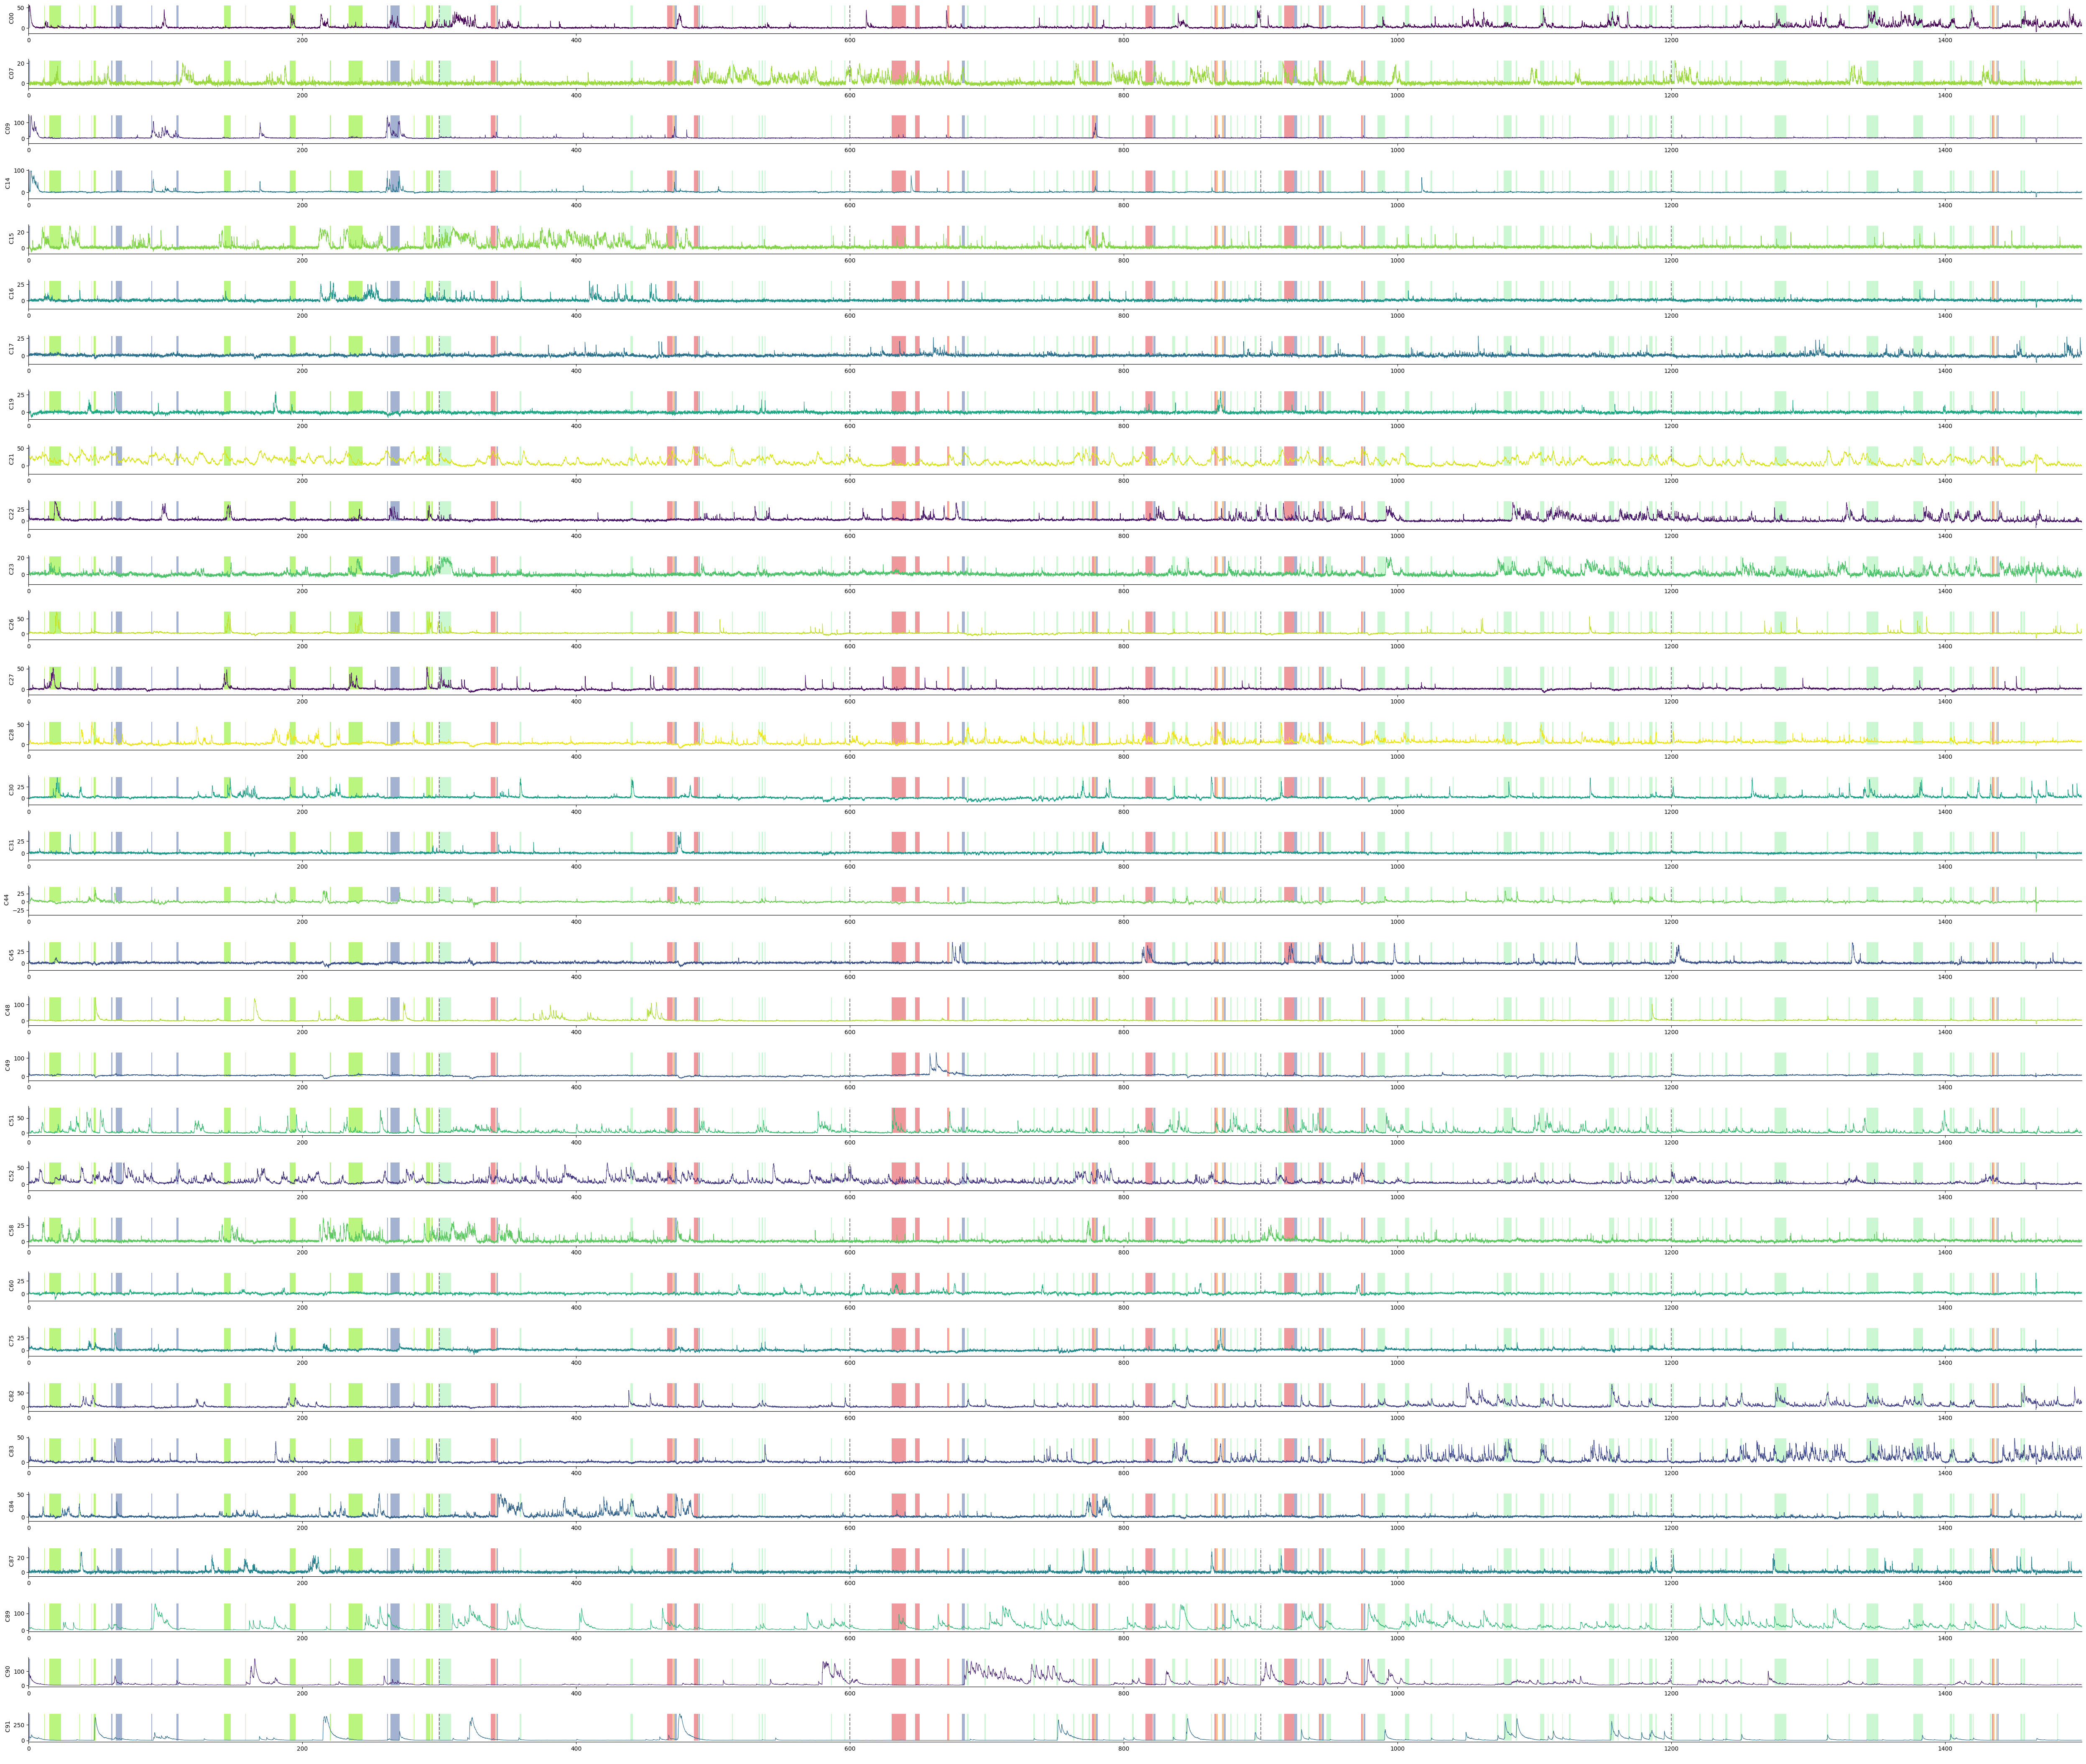

In [8]:
palette = sns.color_palette('viridis',as_cmap=True).colors
# cols = cols_ori[:2] # uncomment this line for full output.
step = int(len(palette)/len(cols))

# UNCOMMENT THIS LINE TO MAKE ALL TRACES BLACK
# palette = ['#000' for i in range(len(palette))]
fig, ax = plt.subplots(len(cols), 1)
fig = plt.gcf()
fig.set_size_inches([50,len(cols)*1.322])
data_x_palette = ["#f28921", "#9af1a8", "#de3339", "#4766a2", "#76ee00"]



color_indices = [i*step for i in range(len(cols))]
rd.seed(18)
rd.shuffle(color_indices)

xlim_max = df_data.max()[' ']

tsvfiles = [f for f in os.listdir('Data') if os.path.isfile('Data/' + f) and '.tsv' in f]
tsvfiles.sort()

for i in range(len(cols)):
    
    max_val = df_data[cols[i]].max()
    min_val = df_data[cols[i]].mean()
    
    for ind,tsv in enumerate(tsvfiles):
        df_sq = pd.read_csv('Data/' + tsv, sep='\t')
        df_sq = df_sq[101:]
        df_sq = df_sq.astype(np.double)
        df_sq['time']-=5.05

        data_x_locations, data_x_colors = generate_squares(df_sq,ind)

        for j,pair in enumerate(data_x_locations):
            ax[i].add_patch(get_rectangle(pair[0],0,pair[1],max_val,data_x_palette[data_x_colors[j]]))
    
    sns.lineplot(data=df_data,x=" ",y=cols[i],ax=ax[i],color=palette[color_indices[i]],lw=0.8)
    for el in segments:
        ax[i].plot([el,el],[min_val,max_val],linestyle='dashed',color='grey')
    
    ax[i].spines['right'].set_visible(False)
    ax[i].spines['top'].set_visible(False)
    ax[i].set_xlim([0,xlim_max])
    
fig.tight_layout()
fig.savefig("CNMFE_AllTraces.jpg",dpi=300)